# Predicting 30-Day Customer Repeat Purchase
## Behavioural, cancellation, TF-IDF and MiniLM semantic features

This notebook implements the complete project using the standalone **UCI Online Retail** dataset (dataset ID 352), containing 541,909 invoice lines from 1 December 2010 to 9 December 2011. The modelling unit is one identified customer at one month-end.

Source: [UCI Machine Learning Repository — Online Retail](https://archive.ics.uci.edu/dataset/352/online+retail). The downloaded workbook is stored locally as `Online Retail 2.xlsx`. Although the UCI page labels the dataset as having no missing values, the notebook audits the downloaded file directly and handles any missing customer IDs or product descriptions found in it.

### Research question
Can the previous 90 days of transactions predict whether a customer makes a valid purchase in the following 30 days, and do semantic product-history features improve performance beyond behavioural baselines?

### Chronological design
- March-June 2011 snapshots: training
- July 2011: model, hyperparameter and threshold selection
- August-October 2011: final rolling evaluation

All feature transformations are fitted on earlier data. Product-cluster centres use descriptions observed through June only. Results are predictive associations, not causal effects of marketing.

## 0. Environment and configuration
The first code cell installs only missing packages. The pretrained model is downloaded on first use and then cached.

In [1]:
import importlib.util, subprocess, sys

required = {
    'pandas': 'pandas', 'numpy': 'numpy', 'openpyxl': 'openpyxl',
    'sklearn': 'scikit-learn', 'matplotlib': 'matplotlib',
    'seaborn': 'seaborn', 'sentence_transformers': 'sentence-transformers'
}
missing = [package for module, package in required.items() if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *missing])
print('Environment ready.')

Environment ready.


In [2]:
from pathlib import Path
import re, warnings, math, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

from sklearn.base import clone
from sklearn.cluster import MiniBatchKMeans
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, roc_auc_score, f1_score,
                             precision_recall_curve, confusion_matrix,
                             silhouette_score, PrecisionRecallDisplay)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# Avoid a harmless progress-widget warning when the notebook runs outside JupyterLab.
warnings.filterwarnings('ignore', message='IProgress not found.*')
from sentence_transformers import SentenceTransformer

warnings.filterwarnings('ignore', category=FutureWarning)
pd.set_option('display.max_columns', 80)
pd.set_option('display.width', 160)
sns.set_theme(style='whitegrid', context='notebook')
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

PROJECT_DIR = Path.cwd()
DATA_PATH = PROJECT_DIR / 'Online Retail 2.xlsx'
SHEET_NAME = 'Online Retail'
OUTPUT_DIR = PROJECT_DIR / 'notebook_outputs'
OUTPUT_DIR.mkdir(exist_ok=True)

SNAPSHOT_DATES = pd.to_datetime([
    '2011-03-31','2011-04-30','2011-05-31','2011-06-30',
    '2011-07-31','2011-08-31','2011-09-30','2011-10-31'
])
TRAIN_END = pd.Timestamp('2011-06-30')
VALIDATION_DATE = pd.Timestamp('2011-07-31')
TEST_DATES = pd.to_datetime(['2011-08-31','2011-09-30','2011-10-31'])
EMBEDDING_MODEL = 'sentence-transformers/all-MiniLM-L6-v2'
K_CANDIDATES = [8, 12, 16, 20]

assert DATA_PATH.exists(), f'Missing source workbook: {DATA_PATH.name}'
print(f'Data: {DATA_PATH.name} | Sheet: {SHEET_NAME}')
print(f'Outputs: {OUTPUT_DIR.name}/')

Data: Online Retail 2.xlsx | Sheet: Online Retail
Outputs: notebook_outputs/


## Stage 1. Raw invoice-line data
One row is one product line within an invoice. Repeated invoice numbers are therefore expected.

In [3]:
raw = pd.read_excel(DATA_PATH, sheet_name=SHEET_NAME, engine='openpyxl')
# Normalize the standalone dataset's official field names to the shorter internal names
# used throughout this notebook. No values are changed by this rename.
raw = raw.rename(columns={'InvoiceNo': 'Invoice', 'UnitPrice': 'Price', 'Customer ID': 'CustomerID'})
expected_columns = ['Invoice','StockCode','Description','Quantity','InvoiceDate','Price','CustomerID','Country']
assert list(raw.columns) == expected_columns, f'Unexpected columns: {raw.columns.tolist()}'
assert len(raw) == 541_909, f'Expected 541,909 rows; found {len(raw):,}'

raw_audit = pd.DataFrame({
    'Metric': ['Rows','Columns','First timestamp','Last timestamp','Missing CustomerID',
               'Missing Description','Exact duplicate rows','Unique invoices','Unique stock codes'],
    'Value': [len(raw), raw.shape[1], raw['InvoiceDate'].min(), raw['InvoiceDate'].max(),
              raw['CustomerID'].isna().sum(), raw['Description'].isna().sum(),
              raw.duplicated().sum(), raw['Invoice'].nunique(), raw['StockCode'].nunique()]
})
display(raw.head(12), raw_audit)

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
5,536365,22752,SET 7 BABUSHKA NESTING BOXES,2,2010-12-01 08:26:00,7.65,17850.0,United Kingdom
6,536365,21730,GLASS STAR FROSTED T-LIGHT HOLDER,6,2010-12-01 08:26:00,4.25,17850.0,United Kingdom
7,536366,22633,HAND WARMER UNION JACK,6,2010-12-01 08:28:00,1.85,17850.0,United Kingdom
8,536366,22632,HAND WARMER RED POLKA DOT,6,2010-12-01 08:28:00,1.85,17850.0,United Kingdom
9,536367,84879,ASSORTED COLOUR BIRD ORNAMENT,32,2010-12-01 08:34:00,1.69,13047.0,United Kingdom


,Metric,Value
0,Rows,541909
1,Columns,8
2,First timestamp,2010-12-01 08:26:00
3,Last timestamp,2011-12-09 12:50:00
4,Missing CustomerID,135080
5,Missing Description,1454
6,Exact duplicate rows,5268
7,Unique invoices,25900
8,Unique stock codes,4070


## Stage 2. Cleaning and transaction classification
Exact duplicate rows are removed and reported. This choice can be changed for a sensitivity analysis. Cancellations remain available for historical cancellation features but never count as positive spending or a positive target.

In [4]:
DROP_EXACT_DUPLICATES = True
data = raw.copy()
data['WasExactDuplicate'] = data.duplicated(keep='first')
if DROP_EXACT_DUPLICATES:
    data = data.loc[~data['WasExactDuplicate']].copy()

data['Invoice'] = data['Invoice'].astype('string').str.strip()
data['StockCode'] = data['StockCode'].astype('string').str.strip()
data['InvoiceDate'] = pd.to_datetime(data['InvoiceDate'], errors='coerce')
data['CustomerID'] = pd.to_numeric(data['CustomerID'], errors='coerce').astype('Int64')
data['Quantity'] = pd.to_numeric(data['Quantity'], errors='coerce')
data['Price'] = pd.to_numeric(data['Price'], errors='coerce')

def clean_description(value):
    if pd.isna(value):
        return pd.NA
    text = str(value).upper().strip()
    text = re.sub(r'[^A-Z0-9 ]+', ' ', text)
    return re.sub(r'\s+', ' ', text).strip() or pd.NA

data['CleanDescription'] = data['Description'].map(clean_description).astype('string')
data['HasCustomerID'] = data['CustomerID'].notna()
data['IsCancellation'] = data['Invoice'].str.upper().str.startswith('C', na=False) | data['Quantity'].lt(0)
data['IsValidPurchase'] = (data['HasCustomerID'] & ~data['IsCancellation'] &
                           data['Quantity'].gt(0) & data['Price'].gt(0) &
                           data['InvoiceDate'].notna())
data['LineRevenue'] = data['Quantity'] * data['Price']
data['PurchaseDate'] = data['InvoiceDate'].dt.normalize()

positive_lines = data.loc[data['IsValidPurchase']].copy()
return_lines = data.loc[data['HasCustomerID'] & data['IsCancellation']].copy()
invalid_or_unidentified = data.loc[~data['IsValidPurchase'] &
                                    ~(data['HasCustomerID'] & data['IsCancellation'])].copy()
return_lines['ReturnedValue'] = return_lines['Quantity'].abs() * return_lines['Price'].clip(lower=0)
return_lines['ReturnedUnits'] = return_lines['Quantity'].abs()

assert positive_lines['CustomerID'].notna().all()
assert positive_lines['Quantity'].gt(0).all() and positive_lines['Price'].gt(0).all()
assert not positive_lines['IsCancellation'].any()

cleaning_audit = pd.DataFrame({
    'Stage': ['Raw rows','Exact duplicates removed','Cleaned rows','Valid positive-purchase lines',
              'Identified cancellation/return lines','Other invalid or unidentified lines'],
    'Rows': [len(raw), int(raw.duplicated().sum()), len(data), len(positive_lines),
             len(return_lines), len(invalid_or_unidentified)]
})
display(cleaning_audit)
display(positive_lines[['Invoice','StockCode','CleanDescription','Quantity','Price','LineRevenue',
                        'HasCustomerID','IsCancellation','IsValidPurchase']].head(10))

,Stage,Rows
0,Raw rows,541909
1,Exact duplicates removed,5268
2,Cleaned rows,536641
3,Valid positive-purchase lines,392692
4,Identified cancellation/return lines,8872
5,Other invalid or unidentified lines,135077


,Invoice,StockCode,CleanDescription,Quantity,Price,LineRevenue,HasCustomerID,IsCancellation,IsValidPurchase
0,536365,85123A,WHITE HANGING HEART T LIGHT HOLDER,6,2.55,15.30,True,False,True
1,536365,71053,WHITE METAL LANTERN,6,3.39,20.34,True,False,True
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2.75,22.00,True,False,True
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,3.39,20.34,True,False,True
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART,6,3.39,20.34,True,False,True
5,536365,22752,SET 7 BABUSHKA NESTING BOXES,2,7.65,15.30,True,False,True
6,536365,21730,GLASS STAR FROSTED T LIGHT HOLDER,6,4.25,25.50,True,False,True
7,536366,22633,HAND WARMER UNION JACK,6,1.85,11.10,True,False,True
8,536366,22632,HAND WARMER RED POLKA DOT,6,1.85,11.10,True,False,True
9,536367,84879,ASSORTED COLOUR BIRD ORNAMENT,32,1.69,54.08,True,False,True


## Stage 3. Invoice-level dataset
Positive product lines are aggregated by customer, invoice and timestamp. The invoice table is used for basket and timing features.

In [5]:
invoice_summary = (
    positive_lines.groupby(['CustomerID','Invoice','InvoiceDate'], observed=True)
    .agg(BasketValue=('LineRevenue','sum'),
         TotalUnits=('Quantity','sum'),
         UniqueProducts=('StockCode','nunique'),
         Country=('Country', lambda s: s.mode().iloc[0] if not s.mode().empty else s.iloc[0]))
    .reset_index()
)
invoice_summary['PurchaseDate'] = invoice_summary['InvoiceDate'].dt.normalize()
invoice_summary['IsWeekend'] = invoice_summary['InvoiceDate'].dt.dayofweek.ge(5).astype(int)

invoice_audit = pd.DataFrame({
    'Metric': ['Positive invoices','Identified customers','Positive line revenue','Invoice basket revenue'],
    'Value': [len(invoice_summary), invoice_summary['CustomerID'].nunique(),
              positive_lines['LineRevenue'].sum(), invoice_summary['BasketValue'].sum()]
})
assert np.isclose(positive_lines['LineRevenue'].sum(), invoice_summary['BasketValue'].sum())
display(invoice_summary.head(10), invoice_audit)

,CustomerID,Invoice,InvoiceDate,BasketValue,TotalUnits,UniqueProducts,Country,PurchaseDate,IsWeekend
0,12346,541431,2011-01-18 10:01:00,77183.60,74215,1,United Kingdom,2011-01-18,0
1,12347,537626,2010-12-07 14:57:00,711.79,319,31,Iceland,2010-12-07,0
2,12347,542237,2011-01-26 14:30:00,475.39,315,29,Iceland,2011-01-26,0
3,12347,549222,2011-04-07 10:43:00,636.25,483,24,Iceland,2011-04-07,0
4,12347,556201,2011-06-09 13:01:00,382.52,196,18,Iceland,2011-06-09,0
5,12347,562032,2011-08-02 08:48:00,584.91,277,22,Iceland,2011-08-02,0
6,12347,573511,2011-10-31 12:25:00,1294.32,676,47,Iceland,2011-10-31,0
7,12347,581180,2011-12-07 15:52:00,224.82,192,11,Iceland,2011-12-07,0
8,12348,539318,2010-12-16 19:09:00,892.80,1254,13,Finland,2010-12-16,0
9,12348,541998,2011-01-25 10:42:00,227.44,601,6,Finland,2011-01-25,0


,Metric,Value
0,Positive invoices,18562.000
1,Identified customers,4338.000
2,Positive line revenue,8887208.894
3,Invoice basket revenue,8887208.894


## Stages 4-7. Customer snapshots, RFM, behaviour and cancellations
For snapshot date `t`, the feature window is the 90-day interval ending after the full snapshot day. The target window is the immediately following 30 days. A customer is eligible only after at least one valid purchase in the feature window.

In [6]:
def _gap_statistics(invoice_dates):
    dates = np.sort(pd.Series(invoice_dates).drop_duplicates().values.astype('datetime64[ns]'))
    if len(dates) < 2:
        return np.nan, np.nan
    gaps = np.diff(dates) / np.timedelta64(1, 'D')
    return float(np.mean(gaps)), float(np.std(gaps, ddof=1)) if len(gaps) > 1 else 0.0

def build_base_snapshot(snapshot_date):
    snapshot_date = pd.Timestamp(snapshot_date).normalize()
    feature_end = snapshot_date + pd.Timedelta(days=1)       # exclusive
    feature_start = feature_end - pd.Timedelta(days=90)
    target_start = feature_end
    target_end = target_start + pd.Timedelta(days=30)        # exclusive

    hist_lines = positive_lines.loc[(positive_lines['InvoiceDate'] >= feature_start) &
                                      (positive_lines['InvoiceDate'] < feature_end)].copy()
    hist_inv = invoice_summary.loc[(invoice_summary['InvoiceDate'] >= feature_start) &
                                   (invoice_summary['InvoiceDate'] < feature_end)].copy()
    future = positive_lines.loc[(positive_lines['InvoiceDate'] >= target_start) &
                                (positive_lines['InvoiceDate'] < target_end)]
    hist_returns = return_lines.loc[(return_lines['InvoiceDate'] >= feature_start) &
                                    (return_lines['InvoiceDate'] < feature_end)].copy()

    line_g = hist_lines.groupby('CustomerID', observed=True)
    snap = line_g.agg(
        LastPurchase=('InvoiceDate','max'),
        FirstPurchaseInWindow=('InvoiceDate','min'),
        Frequency90D=('Invoice','nunique'),
        Monetary90D=('LineRevenue','sum'),
        TotalUnits90D=('Quantity','sum'),
        UniqueProducts90D=('StockCode','nunique'),
        ActivePurchaseDays=('PurchaseDate','nunique'),
        UKLineShare=('Country', lambda s: s.eq('United Kingdom').mean())
    ).reset_index()

    snap['RecencyDays'] = (feature_end - snap['LastPurchase']).dt.total_seconds() / 86400
    snap['HistorySpanDays90D'] = (feature_end - snap['FirstPurchaseInWindow']).dt.total_seconds() / 86400
    snap['IsUK'] = snap['UKLineShare'].ge(0.5).astype(int)

    basket = hist_inv.groupby('CustomerID', observed=True).agg(
        AverageBasketValue=('BasketValue','mean'),
        MaximumBasketValue=('BasketValue','max'),
        WeekendInvoiceShare=('IsWeekend','mean')
    ).reset_index()
    last30 = (hist_inv.loc[hist_inv['InvoiceDate'] >= feature_end - pd.Timedelta(days=30)]
              .groupby('CustomerID', observed=True)['Invoice'].nunique()
              .rename('InvoicesLast30D').reset_index())

    gap_rows = []
    for customer_id, group in hist_inv.groupby('CustomerID', observed=True, sort=False):
        mean_gap, gap_std = _gap_statistics(group['InvoiceDate'])
        gap_rows.append((customer_id, mean_gap, gap_std))
    gaps = pd.DataFrame(gap_rows, columns=['CustomerID','MeanGapDays','GapStdDays'])

    snap = snap.merge(basket, on='CustomerID', how='left').merge(last30, on='CustomerID', how='left')
    snap = snap.merge(gaps, on='CustomerID', how='left')
    snap['InvoicesLast30D'] = snap['InvoicesLast30D'].fillna(0).astype(int)
    snap['HasMultipleInvoices'] = snap['Frequency90D'].ge(2).astype(int)

    if len(hist_returns):
        cancel = hist_returns.groupby('CustomerID', observed=True).agg(
            CancellationLines=('Invoice','size'),
            CancellationInvoices=('Invoice','nunique'),
            ReturnedValue90D=('ReturnedValue','sum'),
            ReturnedUnits90D=('ReturnedUnits','sum'),
            LastCancellation=('InvoiceDate','max')
        ).reset_index()
        snap = snap.merge(cancel, on='CustomerID', how='left')
    else:
        for col in ['CancellationLines','CancellationInvoices','ReturnedValue90D','ReturnedUnits90D']:
            snap[col] = 0
        snap['LastCancellation'] = pd.NaT

    zero_cols = ['CancellationLines','CancellationInvoices','ReturnedValue90D','ReturnedUnits90D']
    snap[zero_cols] = snap[zero_cols].fillna(0)
    snap['HasCancellation'] = snap['CancellationInvoices'].gt(0).astype(int)
    snap['CancellationRate'] = (snap['CancellationInvoices'] /
        (snap['Frequency90D'] + snap['CancellationInvoices']).replace(0, np.nan)).fillna(0)
    snap['DaysSinceLastCancellation'] = (feature_end - snap['LastCancellation']).dt.total_seconds() / 86400

    positive_future_customers = set(future['CustomerID'].dropna().astype(int))
    snap['RepeatPurchase30D'] = snap['CustomerID'].astype(int).isin(positive_future_customers).astype(int)
    snap['SnapshotDate'] = snapshot_date
    snap['FeatureStart'] = feature_start
    snap['FeatureEndExclusive'] = feature_end
    snap['TargetStart'] = target_start
    snap['TargetEndExclusive'] = target_end
    return snap

base_snapshots = pd.concat([build_base_snapshot(d) for d in SNAPSHOT_DATES], ignore_index=True)
assert not base_snapshots.duplicated(['SnapshotDate','CustomerID']).any()
assert (base_snapshots['FeatureEndExclusive'] == base_snapshots['TargetStart']).all()
assert (base_snapshots['TargetEndExclusive'] <= pd.Timestamp('2011-12-01')).all()

snapshot_audit = (base_snapshots.groupby('SnapshotDate')
                  .agg(CustomerSnapshots=('CustomerID','size'),
                       PositiveTargets=('RepeatPurchase30D','sum'),
                       PositiveRate=('RepeatPurchase30D','mean'))
                  .reset_index())
display(snapshot_audit.style.format({'PositiveRate':'{:.1%}'}))

,SnapshotDate,CustomerSnapshots,PositiveTargets,PositiveRate
0,2011-03-31 00:00:00,1776,495,27.9%
1,2011-04-30 00:00:00,1891,670,35.4%
2,2011-05-31 00:00:00,1959,635,32.4%
3,2011-06-30 00:00:00,1969,617,31.3%
4,2011-07-31 00:00:00,2025,643,31.8%
5,2011-08-31 00:00:00,1923,728,37.9%
6,2011-09-30 00:00:00,2151,758,35.2%
7,2011-10-31 00:00:00,2461,1056,42.9%


In [7]:
customer_example = base_snapshots.loc[base_snapshots['CustomerID'].eq(13047), [
    'SnapshotDate','CustomerID','RecencyDays','Frequency90D','Monetary90D',
    'TotalUnits90D','UniqueProducts90D','AverageBasketValue','ActivePurchaseDays',
    'CancellationRate','RepeatPurchase30D'
]].copy()
display(customer_example.round(2))

/var/folders/d1/cgf35sqj53j20gtsw9h1_gm40000gn/T/ipykernel_29250/4132394706.py:6: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(customer_example.round(2))


,SnapshotDate,CustomerID,RecencyDays,Frequency90D,Monetary90D,TotalUnits90D,UniqueProducts90D,AverageBasketValue,ActivePurchaseDays,CancellationRate,RepeatPurchase30D
237,2011-03-31,13047,1.44,2,886.05,404,37,443.02,2,0.50,0
2003,2011-04-30,13047,31.44,2,886.05,404,37,443.02,2,0.33,1
3898,2011-05-31,13047,27.41,2,846.15,369,36,423.08,2,0.33,1
5865,2011-06-30,13047,11.42,2,981.40,350,44,490.70,2,0.33,0
7845,2011-07-31,13047,42.42,2,981.40,350,44,490.70,2,0.50,1
9872,2011-08-31,13047,27.25,2,1010.33,483,47,505.16,2,0.67,0
11828,2011-09-30,13047,57.25,1,447.93,309,26,447.93,1,0.75,1
13999,2011-10-31,13047,17.53,2,998.51,535,53,499.26,2,0.60,1


## Stage 8. Product text representations
Two text representations are compared. TF-IDF is the conventional text baseline. `all-MiniLM-L6-v2` is the frozen pretrained semantic encoder. Both clustering models learn centres only from product descriptions observed before 1 July 2011.

In [8]:
description_table = (positive_lines.loc[positive_lines['CleanDescription'].notna(), ['CleanDescription']]
                     .drop_duplicates().sort_values('CleanDescription').reset_index(drop=True))
train_descriptions = set(positive_lines.loc[
    (positive_lines['InvoiceDate'] < pd.Timestamp('2011-07-01')) &
    positive_lines['CleanDescription'].notna(), 'CleanDescription'
].unique())
description_table['SeenByTrainingEnd'] = description_table['CleanDescription'].isin(train_descriptions)
all_descriptions = description_table['CleanDescription'].tolist()
train_mask = description_table['SeenByTrainingEnd'].to_numpy()

print(f'Unique cleaned descriptions: {len(description_table):,}')
print(f'Descriptions seen through June: {train_mask.sum():,}')
display(description_table.head(10))

Unique cleaned descriptions: 3,841
Descriptions seen through June: 3,336


,CleanDescription,SeenByTrainingEnd
0,10 COLOUR SPACEBOY PEN,True
1,12 COLOURED PARTY BALLOONS,True
2,12 DAISY PEGS IN WOOD BOX,True
3,12 EGG HOUSE PAINTED WOOD,True
4,12 HANGING EGGS HAND PAINTED,False
5,12 IVORY ROSE PEG PLACE SETTINGS,True
6,12 MESSAGE CARDS WITH ENVELOPES,True
7,12 PENCIL SMALL TUBE WOODLAND,True
8,12 PENCILS SMALL TUBE RED RETROSPOT,True
9,12 PENCILS SMALL TUBE SKULL,True


In [9]:
def choose_cluster_count(X_train, candidates, representation_name):
    rows = []
    models = {}
    rng = np.random.default_rng(RANDOM_STATE)
    sample_size = min(2000, X_train.shape[0])
    sample_idx = rng.choice(X_train.shape[0], size=sample_size, replace=False)
    for k in candidates:
        km = MiniBatchKMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=20,
                             batch_size=512, reassignment_ratio=0.01)
        labels = km.fit_predict(X_train)
        score = silhouette_score(X_train[sample_idx], labels[sample_idx], metric='cosine')
        rows.append({'Representation': representation_name, 'K': k, 'SilhouetteCosine': score,
                     'SmallestCluster': int(np.bincount(labels, minlength=k).min()),
                     'LargestCluster': int(np.bincount(labels, minlength=k).max())})
        models[k] = km
    results = pd.DataFrame(rows).sort_values('SilhouetteCosine', ascending=False)
    best_k = int(results.iloc[0]['K'])
    return results, models[best_k]

tfidf_vectorizer = TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True, max_features=8000)
X_tfidf_train = tfidf_vectorizer.fit_transform(description_table.loc[train_mask, 'CleanDescription'])
X_tfidf_all = tfidf_vectorizer.transform(description_table['CleanDescription'])
tfidf_k_results, tfidf_clusterer = choose_cluster_count(X_tfidf_train, K_CANDIDATES, 'TF-IDF')
description_table['TFIDFCluster'] = tfidf_clusterer.predict(X_tfidf_all)
display(tfidf_k_results)

,Representation,K,SilhouetteCosine,SmallestCluster,LargestCluster
0,TF-IDF,8,0.014682,60,2270
3,TF-IDF,20,0.011539,1,2201
2,TF-IDF,16,0.011222,3,2127
1,TF-IDF,12,0.009102,5,2206


In [10]:
embedding_model = SentenceTransformer(EMBEDDING_MODEL)
minilm_embeddings = embedding_model.encode(
    all_descriptions, batch_size=128, show_progress_bar=True,
    normalize_embeddings=True, convert_to_numpy=True
)
assert minilm_embeddings.shape == (len(description_table), 384)
minilm_k_results, minilm_clusterer = choose_cluster_count(
    minilm_embeddings[train_mask], K_CANDIDATES, 'MiniLM'
)
description_table['MiniLMCluster'] = minilm_clusterer.predict(minilm_embeddings)
display(minilm_k_results)

Loading weights:   0%|                                 | 0/103 [00:00<?, ?it/s]

Loading weights: 100%|████████████████████| 103/103 [00:00<00:00, 12746.01it/s]

Batches:   0%|                                          | 0/31 [00:00<?, ?it/s]

Batches:   3%|█                                 | 1/31 [00:00<00:06,  4.54it/s]

Batches:  19%|██████▌                           | 6/31 [00:00<00:01, 21.69it/s]

Batches:  39%|████████████▊                    | 12/31 [00:00<00:00, 33.27it/s]

Batches:  58%|███████████████████▏             | 18/31 [00:00<00:00, 40.62it/s]

Batches:  77%|█████████████████████████▌       | 24/31 [00:00<00:00, 46.25it/s]

Batches:  97%|███████████████████████████████▉ | 30/31 [00:00<00:00, 48.35it/s]

Batches: 100%|█████████████████████████████████| 31/31 [00:00<00:00, 39.47it/s]

,Representation,K,SilhouetteCosine,SmallestCluster,LargestCluster
2,MiniLM,16,0.063555,85,401
3,MiniLM,20,0.063421,22,345
1,MiniLM,12,0.056636,89,496
0,MiniLM,8,0.049392,281,577


In [11]:
def representative_descriptions(X_all, clusterer, labels, name, n_examples=10):
    distances = clusterer.transform(X_all)
    rows = []
    labels = np.asarray(labels)
    for cluster_id in range(clusterer.n_clusters):
        member_idx = np.where(labels == cluster_id)[0]
        nearest = member_idx[np.argsort(distances[member_idx, cluster_id])[:n_examples]]
        rows.append({
            'Representation': name, 'Cluster': cluster_id, 'Products': len(member_idx),
            'RepresentativeDescriptions': ' | '.join(description_table.iloc[nearest]['CleanDescription'])
        })
    return pd.DataFrame(rows)

tfidf_cluster_examples = representative_descriptions(
    X_tfidf_all, tfidf_clusterer, description_table['TFIDFCluster'], 'TF-IDF')
minilm_cluster_examples = representative_descriptions(
    minilm_embeddings, minilm_clusterer, description_table['MiniLMCluster'], 'MiniLM')
cluster_examples = pd.concat([tfidf_cluster_examples, minilm_cluster_examples], ignore_index=True)
display(minilm_cluster_examples)
cluster_examples.to_csv(OUTPUT_DIR / 'product_cluster_examples.csv', index=False)

,Representation,Cluster,Products,RepresentativeDescriptions
0,MiniLM,0,166,SMALL SILVER FLOWER CANDLE POT | SMALL REGAL S...
1,MiniLM,1,268,VINTAGE BEAD PINK EVENING BAG | BLUE STRIPES S...
2,MiniLM,2,244,PINK POLKADOT WRAP | PINK PAISLEY ROSE GIFT WR...
3,MiniLM,3,229,HEART WOODEN CHRISTMAS DECORATION | CHRISTMAS ...
4,MiniLM,4,94,SET OF 10 LANTERNS FAIRY LIGHT STAR | SET 6 BL...
5,MiniLM,5,128,FRENCH BLUE METAL DOOR SIGN 1 | FRENCH BLUE ME...
6,MiniLM,6,195,RED 3 PIECE RETROSPOT CUTLERY SET | RED POLKAD...
7,MiniLM,7,254,BUNNY EGG BOX | PINK BUNNY EASTER EGG BASKET |...
8,MiniLM,8,372,LUNCH BOX WITH CUTLERY FAIRY CAKES | STRAWBERR...
9,MiniLM,9,231,MIRROR LOVE BIRD T LIGHT HOLDER | VINTAGE GLAS...


## Stages 9-10. Semantic customer features and final model table
Product-cluster spend shares, cluster count and Shannon diversity are calculated inside each customer's 90-day window. CustomerID identifies rows but is never used as a predictor.

In [12]:
description_to_tfidf = description_table.set_index('CleanDescription')['TFIDFCluster'].to_dict()
description_to_minilm = description_table.set_index('CleanDescription')['MiniLMCluster'].to_dict()
positive_lines['TFIDFCluster'] = positive_lines['CleanDescription'].map(description_to_tfidf)
positive_lines['MiniLMCluster'] = positive_lines['CleanDescription'].map(description_to_minilm)
assert positive_lines[['TFIDFCluster','MiniLMCluster']].notna().all().all()

def build_cluster_features(snapshot_date, cluster_column, prefix, n_clusters):
    snapshot_date = pd.Timestamp(snapshot_date).normalize()
    end = snapshot_date + pd.Timedelta(days=1)
    start = end - pd.Timedelta(days=90)
    hist = positive_lines.loc[(positive_lines['InvoiceDate'] >= start) &
                              (positive_lines['InvoiceDate'] < end),
                              ['CustomerID','LineRevenue',cluster_column]].copy()
    spend = hist.groupby(['CustomerID', cluster_column], observed=True)['LineRevenue'].sum().rename('Spend').reset_index()
    spend['Share'] = spend['Spend'] / spend.groupby('CustomerID', observed=True)['Spend'].transform('sum')
    pivot = spend.pivot(index='CustomerID', columns=cluster_column, values='Share').fillna(0)
    pivot = pivot.reindex(columns=range(n_clusters), fill_value=0)
    pivot.columns = [f'{prefix}Cluster{int(c):02d}Share' for c in pivot.columns]
    out = pivot.reset_index()
    share_cols = [c for c in out.columns if c.endswith('Share')]
    share_values = out[share_cols].to_numpy()
    out[f'{prefix}ClusterCount'] = (share_values > 0).sum(axis=1)
    out[f'{prefix}Diversity'] = -(share_values * np.log(share_values + 1e-12)).sum(axis=1)
    out['SnapshotDate'] = snapshot_date
    return out

tfidf_feature_frames = [build_cluster_features(d, 'TFIDFCluster', 'TFIDF', tfidf_clusterer.n_clusters)
                         for d in SNAPSHOT_DATES]
minilm_feature_frames = [build_cluster_features(d, 'MiniLMCluster', 'MiniLM', minilm_clusterer.n_clusters)
                         for d in SNAPSHOT_DATES]
tfidf_customer_features = pd.concat(tfidf_feature_frames, ignore_index=True)
minilm_customer_features = pd.concat(minilm_feature_frames, ignore_index=True)

model_data = (base_snapshots
              .merge(tfidf_customer_features, on=['SnapshotDate','CustomerID'], how='left')
              .merge(minilm_customer_features, on=['SnapshotDate','CustomerID'], how='left'))
semantic_cols = [c for c in model_data if c.startswith(('TFIDF','MiniLM'))]
model_data[semantic_cols] = model_data[semantic_cols].fillna(0)

for col in ['Frequency90D','Monetary90D','TotalUnits90D','UniqueProducts90D',
            'AverageBasketValue','MaximumBasketValue','ReturnedValue90D','ReturnedUnits90D']:
    model_data[f'Log{col}'] = np.log1p(model_data[col].clip(lower=0))

assert not model_data.duplicated(['SnapshotDate','CustomerID']).any()
assert model_data['CustomerID'].notna().all()
print(f'Final customer-snapshot rows: {len(model_data):,}')
display(model_data.head())
model_data.to_csv(OUTPUT_DIR / 'customer_snapshot_features.csv', index=False)

Final customer-snapshot rows: 16,155


,CustomerID,LastPurchase,FirstPurchaseInWindow,Frequency90D,Monetary90D,TotalUnits90D,UniqueProducts90D,ActivePurchaseDays,UKLineShare,RecencyDays,HistorySpanDays90D,IsUK,AverageBasketValue,MaximumBasketValue,WeekendInvoiceShare,InvoicesLast30D,MeanGapDays,GapStdDays,HasMultipleInvoices,CancellationLines,CancellationInvoices,ReturnedValue90D,ReturnedUnits90D,LastCancellation,HasCancellation,CancellationRate,DaysSinceLastCancellation,RepeatPurchase30D,SnapshotDate,FeatureStart,FeatureEndExclusive,TargetStart,TargetEndExclusive,TFIDFCluster00Share,TFIDFCluster01Share,TFIDFCluster02Share,TFIDFCluster03Share,TFIDFCluster04Share,TFIDFCluster05Share,TFIDFCluster06Share,TFIDFCluster07Share,TFIDFClusterCount,TFIDFDiversity,MiniLMCluster00Share,MiniLMCluster01Share,MiniLMCluster02Share,MiniLMCluster03Share,MiniLMCluster04Share,MiniLMCluster05Share,MiniLMCluster06Share,MiniLMCluster07Share,MiniLMCluster08Share,MiniLMCluster09Share,MiniLMCluster10Share,MiniLMCluster11Share,MiniLMCluster12Share,MiniLMCluster13Share,MiniLMCluster14Share,MiniLMCluster15Share,MiniLMClusterCount,MiniLMDiversity,LogFrequency90D,LogMonetary90D,LogTotalUnits90D,LogUniqueProducts90D,LogAverageBasketValue,LogMaximumBasketValue,LogReturnedValue90D,LogReturnedUnits90D
0,12346,2011-01-18 10:01:00,2011-01-18 10:01:00,1,77183.60,74215,1,1,1.0,72.582639,72.582639,1,77183.600,77183.60,0.0,0,NaN,NaN,0,1.0,1.0,77183.60,74215.0,2011-01-18 10:17:00,1,0.500,72.571528,0,2011-03-31,2011-01-01,2011-04-01,2011-04-01,2011-05-01,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,1.000000,1,-1.000089e-12,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.0,0.000000,1,-1.000089e-12,0.693147,11.253955,11.214735,0.693147,11.253955,11.253955,11.253955,11.214735
1,12347,2011-01-26 14:30:00,2011-01-26 14:30:00,1,475.39,315,29,1,0.0,64.395833,64.395833,0,475.390,475.39,0.0,0,NaN,NaN,0,0.0,0.0,0.00,0.0,NaT,0,0.000,NaN,1,2011-03-31,2011-01-01,2011-04-01,2011-04-01,2011-05-01,0.128105,0.089400,0.000000,0.026505,0.03576,0.000000,0.087591,0.632638,6,1.197399e+00,0.085824,0.089400,0.000000,0.000000,0.041650,0.000000,0.132312,0.169124,0.196365,0.026505,0.026294,0.000000,0.000000,0.032058,0.0,0.200467,10,2.071146e+00,0.693147,6.166237,5.755742,3.401197,6.166237,6.166237,0.000000,0.000000
2,12348,2011-01-25 10:42:00,2011-01-25 10:42:00,1,227.44,601,6,1,0.0,65.554167,65.554167,0,227.440,227.44,0.0,0,NaN,NaN,0,0.0,0.0,0.00,0.0,NaT,0,0.000,NaN,1,2011-03-31,2011-01-01,2011-04-01,2011-04-01,2011-05-01,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.734435,0.265565,2,5.787972e-01,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.273303,0.0,0.726697,2,5.865163e-01,0.693147,5.431274,6.400257,1.945910,5.431274,5.431274,0.000000,0.000000
3,12350,2011-02-02 16:01:00,2011-02-02 16:01:00,1,334.40,197,17,1,0.0,57.332639,57.332639,0,334.400,334.40,0.0,0,NaN,NaN,0,0.0,0.0,0.00,0.0,NaT,0,0.000,NaN,0,2011-03-31,2011-01-01,2011-04-01,2011-04-01,2011-05-01,0.097787,0.061005,0.202751,0.000000,0.00000,0.150718,0.000000,0.487739,5,1.356910e+00,0.000000,0.089713,0.150718,0.000000,0.000000,0.202751,0.158792,0.000000,0.174342,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.223684,6,1.756770e+00,0.693147,5.815324,5.288267,2.890372,5.815324,5.815324,0.000000,0.000000
4,12352,2011-03-22 16:08:00,2011-02-16 12:33:00,5,1561.81,254,26,4,0.0,9.327778,43.477083,0,312.362,840.30,0.0,2,8.537326,7.3326,1,10.0,3.0,960.63,66.0,2011-03-22 16:07:00,1,0.375,9.328472,0,2011-03-31,2011-01-01,2011-04-01,2011-04-01,2011-05-01,0.090024,0.000000,0.022666,0.000000,0.00000,0.000000,0.060315,0.826996,4,6.290493e-01,0.000000,0.034287,0.000000,0.022218,0.019016,0.041778,0.035152,0.057241,0.668039,0.000000,0.022897,0.010885,0.014983,0.022282,0.0,0.051223,12,1.394755e+00,1.791759,7.354241,5.541264,3.295837,5.747359,6.734948,6.868630,4.204693


## Stages 11-12. Preprocessing and feature ablations
The primary ablation uses the same three feature stages for both model families: **RFM**, **extended behaviour including cancellation history**, and **extended behaviour plus MiniLM semantic features**. TF-IDF product groups provide one additional conventional text benchmark. This structure separates gains from richer features, nonlinear modelling and pretrained embeddings. All imputers and scalers are fitted inside model pipelines on training rows only.

In [13]:
RFM_FEATURES = ['RecencyDays','LogFrequency90D','LogMonetary90D']
BEHAVIOUR_FEATURES = RFM_FEATURES + [
    'LogTotalUnits90D','LogUniqueProducts90D','LogAverageBasketValue','LogMaximumBasketValue',
    'ActivePurchaseDays','InvoicesLast30D','MeanGapDays','GapStdDays','WeekendInvoiceShare',
    'HistorySpanDays90D','HasMultipleInvoices','IsUK'
]
CANCELLATION_FEATURES = BEHAVIOUR_FEATURES + [
    'CancellationLines','CancellationInvoices','CancellationRate','HasCancellation',
    'LogReturnedValue90D','LogReturnedUnits90D','DaysSinceLastCancellation'
]
TFIDF_FEATURES = CANCELLATION_FEATURES + [c for c in model_data if c.startswith('TFIDF')]
MINILM_FEATURES = CANCELLATION_FEATURES + [c for c in model_data if c.startswith('MiniLM')]

feature_sets = {
    'A_RFM': RFM_FEATURES,
    'B_Behaviour': BEHAVIOUR_FEATURES,
    'C_Behaviour_Cancellation': CANCELLATION_FEATURES,
    'D_TFIDF': TFIDF_FEATURES,
    'E_MiniLM': MINILM_FEATURES
}
feature_set_summary = pd.DataFrame([{'Dataset': k, 'Predictors': len(v)} for k, v in feature_sets.items()])
display(feature_set_summary)

,Dataset,Predictors
0,A_RFM,3
1,B_Behaviour,15
2,C_Behaviour_Cancellation,22
3,D_TFIDF,32
4,E_MiniLM,40


## Stage 13. Models, validation and rolling evaluation
PR-AUC is primary. ROC-AUC, F1 and lift among the highest-scored 20% are secondary. Logistic regression and gradient boosting are each tested with RFM, extended behaviour, and extended behaviour plus MiniLM. Every supervised decision, including F1 thresholds and gradient-boosting settings, is fixed using July before the three final months are evaluated.

In [14]:
TARGET = 'RepeatPurchase30D'
train_df = model_data.loc[model_data['SnapshotDate'] <= TRAIN_END].copy()
val_df = model_data.loc[model_data['SnapshotDate'].eq(VALIDATION_DATE)].copy()
test_df = model_data.loc[model_data['SnapshotDate'].isin(TEST_DATES)].copy()
assert train_df['SnapshotDate'].max() < val_df['SnapshotDate'].min() < test_df['SnapshotDate'].min()

split_summary = pd.DataFrame({
    'Split': ['Training','Validation','Final rolling test'],
    'Snapshot dates': [f'{train_df.SnapshotDate.min().date()} to {train_df.SnapshotDate.max().date()}',
                       str(VALIDATION_DATE.date()),
                       f'{test_df.SnapshotDate.min().date()} to {test_df.SnapshotDate.max().date()}'],
    'Rows': [len(train_df), len(val_df), len(test_df)],
    'Positive rate': [train_df[TARGET].mean(), val_df[TARGET].mean(), test_df[TARGET].mean()]
})
display(split_summary.style.format({'Positive rate':'{:.1%}'}))

,Split,Snapshot dates,Rows,Positive rate
0,Training,2011-03-31 to 2011-06-30,7595,31.8%
1,Validation,2011-07-31,2025,31.8%
2,Final rolling test,2011-08-31 to 2011-10-31,6535,38.9%


In [15]:
def lift_at_fraction(y_true, scores, fraction=0.20):
    y_true = np.asarray(y_true)
    scores = np.asarray(scores)
    if len(scores) == 0 or np.allclose(scores, scores[0]):
        return 1.0 if y_true.mean() > 0 else np.nan
    n_top = max(1, int(np.ceil(len(y_true) * fraction)))
    top_rate = y_true[np.argsort(scores)[::-1][:n_top]].mean()
    base_rate = y_true.mean()
    return float(top_rate / base_rate) if base_rate > 0 else np.nan

def best_f1_threshold(y_true, scores):
    precision, recall, thresholds = precision_recall_curve(y_true, scores)
    f1 = 2 * precision[:-1] * recall[:-1] / (precision[:-1] + recall[:-1] + 1e-12)
    return float(thresholds[int(np.nanargmax(f1))]) if len(thresholds) else 0.5

def classification_metrics(y_true, scores, threshold):
    y_true = np.asarray(y_true)
    scores = np.asarray(scores)
    pred = (scores >= threshold).astype(int)
    return {
        'PR_AUC': average_precision_score(y_true, scores),
        'ROC_AUC': roc_auc_score(y_true, scores) if len(np.unique(y_true)) == 2 else np.nan,
        'F1': f1_score(y_true, pred, zero_division=0),
        'LiftAt20': lift_at_fraction(y_true, scores, 0.20),
        'Threshold': threshold
    }

def logistic_model():
    return Pipeline([
        ('imputer', SimpleImputer(strategy='median', add_indicator=True)),
        ('scaler', StandardScaler()),
        ('model', LogisticRegression(max_iter=2500, class_weight='balanced', random_state=RANDOM_STATE))
    ])

def boosting_model(params):
    return Pipeline([
        ('imputer', SimpleImputer(strategy='median', add_indicator=True)),
        ('model', HistGradientBoostingClassifier(
            max_iter=250, random_state=RANDOM_STATE, class_weight='balanced',
            early_stopping=True, validation_fraction=0.15, **params))
    ])

In [16]:
# Small, visible July-only tuning experiment for gradient boosting.
boosting_candidates = [
    {'learning_rate': 0.05, 'max_leaf_nodes': 7,  'l2_regularization': 0.1},
    {'learning_rate': 0.05, 'max_leaf_nodes': 15, 'l2_regularization': 0.1},
    {'learning_rate': 0.10, 'max_leaf_nodes': 15, 'l2_regularization': 0.1},
    {'learning_rate': 0.05, 'max_leaf_nodes': 31, 'l2_regularization': 1.0}
]
tuning_rows = []
for params in boosting_candidates:
    candidate = boosting_model(params)
    candidate.fit(train_df[CANCELLATION_FEATURES], train_df[TARGET])
    score = candidate.predict_proba(val_df[CANCELLATION_FEATURES])[:, 1]
    tuning_rows.append({**params, 'July_PR_AUC': average_precision_score(val_df[TARGET], score)})
boosting_tuning = pd.DataFrame(tuning_rows).sort_values('July_PR_AUC', ascending=False)
BEST_BOOSTING_PARAMS = {k: boosting_tuning.iloc[0][k] for k in
                        ['learning_rate','max_leaf_nodes','l2_regularization']}
BEST_BOOSTING_PARAMS['max_leaf_nodes'] = int(BEST_BOOSTING_PARAMS['max_leaf_nodes'])
display(boosting_tuning)
print('Selected settings:', BEST_BOOSTING_PARAMS)

,learning_rate,max_leaf_nodes,l2_regularization,July_PR_AUC
0,0.05,7,0.1,0.615643
2,0.10,15,0.1,0.611135
1,0.05,15,0.1,0.610531
3,0.05,31,1.0,0.606318


Selected settings: {'learning_rate': np.float64(0.05), 'max_leaf_nodes': 7, 'l2_regularization': np.float64(0.1)}


In [17]:
model_specs = {
    'Logistic RFM': (logistic_model(), RFM_FEATURES),
    'Logistic Behaviour': (logistic_model(), CANCELLATION_FEATURES),
    'Logistic + MiniLM': (logistic_model(), MINILM_FEATURES),
    'Boosting RFM': (boosting_model(BEST_BOOSTING_PARAMS), RFM_FEATURES),
    'Boosting Behaviour': (boosting_model(BEST_BOOSTING_PARAMS), CANCELLATION_FEATURES),
    'Boosting + TFIDF': (boosting_model(BEST_BOOSTING_PARAMS), TFIDF_FEATURES),
    'Boosting + MiniLM': (boosting_model(BEST_BOOSTING_PARAMS), MINILM_FEATURES)
}

validation_rows = []
selected_thresholds = {}
validation_fits = {}

# Majority baseline: constant score and the training majority class.
majority_score = np.repeat(train_df[TARGET].mean(), len(val_df))
majority_class = int(train_df[TARGET].mean() >= 0.5)
majority_threshold = 0.0 if majority_class == 1 else 1.0
validation_rows.append({'Model': 'Majority baseline',
                        **classification_metrics(val_df[TARGET], majority_score, majority_threshold)})
selected_thresholds['Majority baseline'] = majority_threshold

# Recency rule: more recent customers receive higher scores.
recency_score = np.exp(-val_df['RecencyDays'].to_numpy() / 30.0)
recency_threshold = best_f1_threshold(val_df[TARGET], recency_score)
validation_rows.append({'Model': 'Recency rule',
                        **classification_metrics(val_df[TARGET], recency_score, recency_threshold)})
selected_thresholds['Recency rule'] = recency_threshold

for name, (estimator, features) in model_specs.items():
    fitted = clone(estimator).fit(train_df[features], train_df[TARGET])
    scores = fitted.predict_proba(val_df[features])[:, 1]
    threshold = best_f1_threshold(val_df[TARGET], scores)
    validation_rows.append({'Model': name, **classification_metrics(val_df[TARGET], scores, threshold)})
    selected_thresholds[name] = threshold
    validation_fits[name] = fitted

validation_results = pd.DataFrame(validation_rows).sort_values('PR_AUC', ascending=False)
SELECTED_MODEL = validation_results.iloc[0]['Model']
SELECTED_LEARNED_MODEL = next(m for m in validation_results['Model'] if m in model_specs)
display(validation_results.style.format({'PR_AUC':'{:.3f}','ROC_AUC':'{:.3f}',
                                         'F1':'{:.3f}','LiftAt20':'{:.2f}','Threshold':'{:.3f}'}))
print(f'Primary model selected using July only: {SELECTED_MODEL}')
validation_results.to_csv(OUTPUT_DIR / 'validation_results.csv', index=False)

,Model,PR_AUC,ROC_AUC,F1,LiftAt20,Threshold
7,Boosting + TFIDF,0.616,0.731,0.565,2.05,0.496
6,Boosting Behaviour,0.616,0.725,0.562,2.08,0.494
8,Boosting + MiniLM,0.615,0.726,0.565,2.03,0.471
4,Logistic + MiniLM,0.612,0.724,0.570,2.08,0.470
3,Logistic Behaviour,0.609,0.722,0.560,2.02,0.456
5,Boosting RFM,0.598,0.714,0.555,2.01,0.500
2,Logistic RFM,0.595,0.715,0.556,1.99,0.509
1,Recency rule,0.407,0.617,0.505,1.38,0.192
0,Majority baseline,0.318,0.500,0.000,1.00,1.000


Primary model selected using July only: Boosting + TFIDF


In [18]:
rolling_metric_rows = []
prediction_rows = []
final_fitted_models = {}

for test_date in TEST_DATES:
    rolling_train = model_data.loc[model_data['SnapshotDate'] < test_date].copy()
    month_test = model_data.loc[model_data['SnapshotDate'].eq(test_date)].copy()
    y_test = month_test[TARGET].to_numpy()

    monthly_scores = {}
    monthly_scores['Majority baseline'] = np.repeat(rolling_train[TARGET].mean(), len(month_test))
    monthly_scores['Recency rule'] = np.exp(-month_test['RecencyDays'].to_numpy() / 30.0)

    for name, (estimator, features) in model_specs.items():
        fitted = clone(estimator).fit(rolling_train[features], rolling_train[TARGET])
        monthly_scores[name] = fitted.predict_proba(month_test[features])[:, 1]
        final_fitted_models[(name, test_date)] = fitted

    for name, scores in monthly_scores.items():
        threshold = selected_thresholds[name]
        metrics = classification_metrics(y_test, scores, threshold)
        rolling_metric_rows.append({'SnapshotDate': test_date, 'Model': name,
                                    'Rows': len(month_test), 'PositiveRate': y_test.mean(), **metrics})
        for row_id, customer_id, y, score in zip(month_test.index, month_test['CustomerID'], y_test, scores):
            prediction_rows.append({'RowID': row_id, 'SnapshotDate': test_date, 'CustomerID': int(customer_id),
                                    'Model': name, 'Actual': int(y), 'Score': float(score),
                                    'Prediction': int(score >= threshold)})

rolling_results = pd.DataFrame(rolling_metric_rows)
predictions = pd.DataFrame(prediction_rows)

pooled_rows = []
for name, group in predictions.groupby('Model'):
    pooled_rows.append({'Model': name, **classification_metrics(
        group['Actual'], group['Score'], selected_thresholds[name])})
pooled_results = pd.DataFrame(pooled_rows).sort_values('PR_AUC', ascending=False)

display(Markdown('### Final pooled results: August-October'))
display(pooled_results.style.format({'PR_AUC':'{:.3f}','ROC_AUC':'{:.3f}',
                                     'F1':'{:.3f}','LiftAt20':'{:.2f}','Threshold':'{:.3f}'}))
display(Markdown('### Results by evaluation month'))
display(rolling_results.sort_values(['SnapshotDate','PR_AUC'], ascending=[True,False])
        .style.format({'PositiveRate':'{:.1%}','PR_AUC':'{:.3f}','ROC_AUC':'{:.3f}',
                       'F1':'{:.3f}','LiftAt20':'{:.2f}','Threshold':'{:.3f}'}))
rolling_results.to_csv(OUTPUT_DIR / 'rolling_monthly_results.csv', index=False)
pooled_results.to_csv(OUTPUT_DIR / 'final_pooled_results.csv', index=False)
predictions.to_csv(OUTPUT_DIR / 'final_test_predictions.csv', index=False)

### Final pooled results: August-October

,Model,PR_AUC,ROC_AUC,F1,LiftAt20,Threshold
0,Boosting + MiniLM,0.638,0.700,0.567,1.80,0.471
2,Boosting Behaviour,0.638,0.700,0.559,1.76,0.494
1,Boosting + TFIDF,0.637,0.701,0.560,1.77,0.496
4,Logistic + MiniLM,0.634,0.696,0.567,1.78,0.470
5,Logistic Behaviour,0.634,0.696,0.568,1.76,0.456
3,Boosting RFM,0.630,0.692,0.544,1.78,0.500
6,Logistic RFM,0.625,0.687,0.549,1.76,0.509
8,Recency rule,0.420,0.552,0.540,1.10,0.192
7,Majority baseline,0.407,0.526,0.000,1.14,1.000


### Results by evaluation month

,SnapshotDate,Model,Rows,PositiveRate,PR_AUC,ROC_AUC,F1,LiftAt20,Threshold
6,2011-08-31 00:00:00,Boosting Behaviour,1923,37.9%,0.652,0.723,0.576,1.81,0.494
8,2011-08-31 00:00:00,Boosting + MiniLM,1923,37.9%,0.652,0.719,0.584,1.87,0.471
3,2011-08-31 00:00:00,Logistic Behaviour,1923,37.9%,0.649,0.719,0.580,1.85,0.456
7,2011-08-31 00:00:00,Boosting + TFIDF,1923,37.9%,0.649,0.723,0.580,1.85,0.496
4,2011-08-31 00:00:00,Logistic + MiniLM,1923,37.9%,0.648,0.714,0.592,1.85,0.470
5,2011-08-31 00:00:00,Boosting RFM,1923,37.9%,0.642,0.716,0.562,1.85,0.500
2,2011-08-31 00:00:00,Logistic RFM,1923,37.9%,0.636,0.711,0.570,1.85,0.509
1,2011-08-31 00:00:00,Recency rule,1923,37.9%,0.445,0.588,0.541,1.28,0.192
0,2011-08-31 00:00:00,Majority baseline,1923,37.9%,0.379,0.500,0.000,1.00,1.000
17,2011-09-30 00:00:00,Boosting + MiniLM,2151,35.2%,0.584,0.677,0.526,1.83,0.471


## Results visualisation

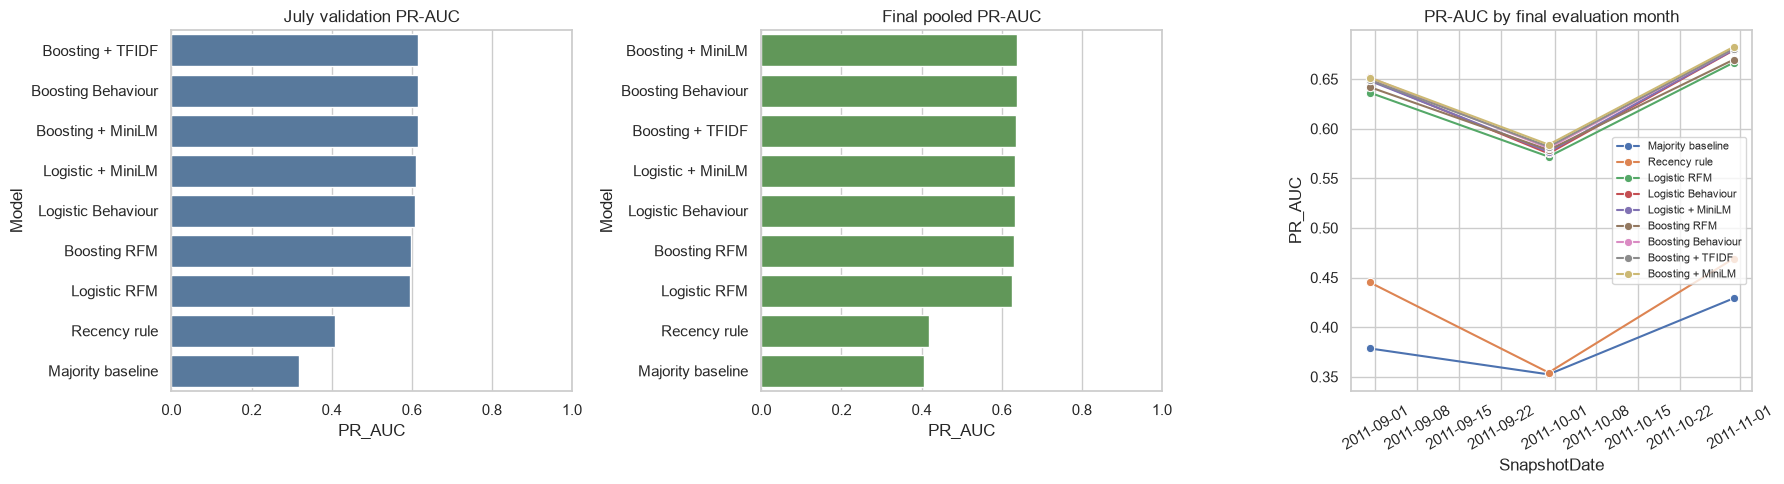

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.barplot(data=validation_results, y='Model', x='PR_AUC', color='#4C78A8', ax=axes[0])
axes[0].set_title('July validation PR-AUC'); axes[0].set_xlim(0, 1)
sns.barplot(data=pooled_results, y='Model', x='PR_AUC', color='#59A14F', ax=axes[1])
axes[1].set_title('Final pooled PR-AUC'); axes[1].set_xlim(0, 1)
sns.lineplot(data=rolling_results, x='SnapshotDate', y='PR_AUC', hue='Model', marker='o', ax=axes[2])
axes[2].set_title('PR-AUC by final evaluation month')
axes[2].tick_params(axis='x', rotation=30); axes[2].legend(fontsize=8, loc='best')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'model_comparison.png', dpi=180, bbox_inches='tight')
plt.show()

## Model interpretation and error analysis
Permutation importance measures the decrease in October PR-AUC after shuffling one feature. It describes predictive dependence, not causality.

### Permutation importance: Boosting + TFIDF

,Feature,ImportanceMean,ImportanceStd
7,ActivePurchaseDays,0.128466,0.009748
1,LogFrequency90D,0.006108,0.002500
0,RecencyDays,0.004562,0.001785
4,LogUniqueProducts90D,0.003349,0.000497
10,GapStdDays,0.003257,0.001575
9,MeanGapDays,0.002551,0.000737
23,TFIDFCluster01Share,0.002392,0.001118
2,LogMonetary90D,0.002171,0.000564
12,HistorySpanDays90D,0.001856,0.001946
3,LogTotalUnits90D,0.001263,0.001261


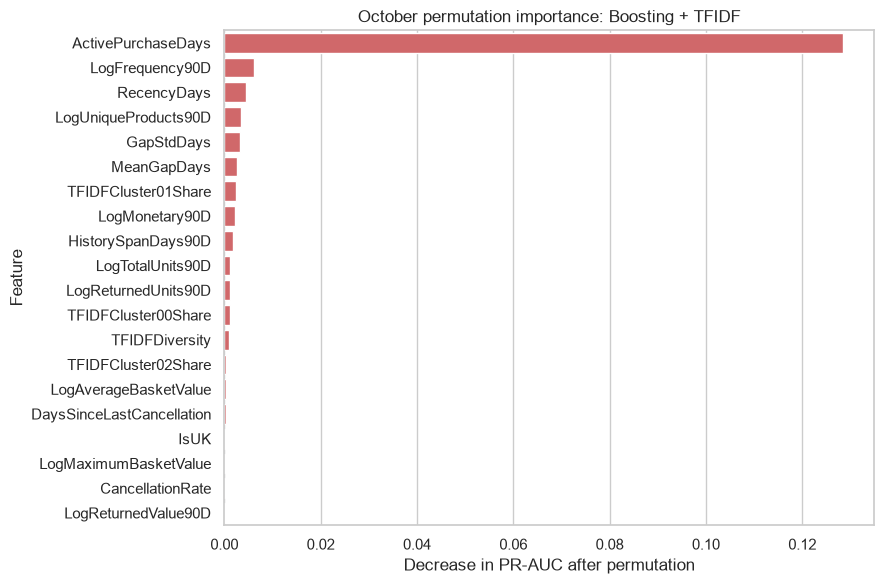

In [20]:
# Interpretation follows the July-selected learned model; the test set does not choose it.
INTERPRETED_MODEL = SELECTED_LEARNED_MODEL
best_features = model_specs[INTERPRETED_MODEL][1]
october_date = TEST_DATES[-1]
october = model_data.loc[model_data['SnapshotDate'].eq(october_date)].copy()
best_october_fit = final_fitted_models[(INTERPRETED_MODEL, october_date)]

perm = permutation_importance(
    best_october_fit, october[best_features], october[TARGET],
    scoring='average_precision', n_repeats=8, random_state=RANDOM_STATE, n_jobs=-1
)
importance = (pd.DataFrame({'Feature': best_features, 'ImportanceMean': perm.importances_mean,
                            'ImportanceStd': perm.importances_std})
              .sort_values('ImportanceMean', ascending=False).head(20))
display(Markdown(f'### Permutation importance: {INTERPRETED_MODEL}'))
display(importance)

plt.figure(figsize=(9, 6))
sns.barplot(data=importance, y='Feature', x='ImportanceMean', color='#E15759')
plt.title(f'October permutation importance: {INTERPRETED_MODEL}')
plt.xlabel('Decrease in PR-AUC after permutation')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'permutation_importance.png', dpi=180, bbox_inches='tight')
plt.show()
importance.to_csv(OUTPUT_DIR / 'permutation_importance.csv', index=False)

In [21]:
best_predictions = predictions.loc[predictions['Model'].eq(INTERPRETED_MODEL)].copy()
best_predictions['ErrorType'] = np.select(
    [(best_predictions['Actual'].eq(1) & best_predictions['Prediction'].eq(1)),
     (best_predictions['Actual'].eq(0) & best_predictions['Prediction'].eq(0)),
     (best_predictions['Actual'].eq(0) & best_predictions['Prediction'].eq(1)),
     (best_predictions['Actual'].eq(1) & best_predictions['Prediction'].eq(0))],
    ['True positive','True negative','False positive','False negative'], default='Unknown')

error_features = model_data[['SnapshotDate','CustomerID','RecencyDays','Frequency90D','Monetary90D',
                             'UniqueProducts90D','CancellationRate']].copy()
error_detail = best_predictions.merge(error_features, on=['SnapshotDate','CustomerID'], how='left')
error_summary = error_detail.groupby('ErrorType').agg(
    Customers=('CustomerID','size'),
    MedianRecency=('RecencyDays','median'),
    MedianFrequency=('Frequency90D','median'),
    MedianSpend=('Monetary90D','median'),
    MedianUniqueProducts=('UniqueProducts90D','median'),
    MedianCancellationRate=('CancellationRate','median')
).reset_index()
display(error_summary.round(2))
error_summary.to_csv(OUTPUT_DIR / 'error_analysis_summary.csv', index=False)

,ErrorType,Customers,MedianRecency,MedianFrequency,MedianSpend,MedianUniqueProducts,MedianCancellationRate
0,False negative,1164,36.52,1.0,324.14,19.0,0.0
1,False positive,998,24.42,2.0,780.16,37.0,0.0
2,True negative,2995,32.55,1.0,302.46,17.0,0.0
3,True positive,1378,17.49,3.0,1064.20,46.0,0.0


## Evidence-based conclusions
The next cell generates conclusions from the executed results. The compact ablation table compares each feature stage within the same model family, so improvements are not confused with a change of algorithm. A semantic stage is considered useful only if it improves held-out performance over that family's behavioural model.

In [22]:
result_lookup = pooled_results.set_index('Model')
selected_final = result_lookup.loc[SELECTED_MODEL]
posthoc_best = pooled_results.iloc[0]
monthly_best = rolling_results.loc[rolling_results.groupby('SnapshotDate')['PR_AUC'].idxmax(),
                                   ['SnapshotDate','Model','PR_AUC']]

ablation_rows = []
for family, rfm_name, behaviour_name, minilm_name in [
    ('Logistic regression', 'Logistic RFM', 'Logistic Behaviour', 'Logistic + MiniLM'),
    ('Gradient boosting', 'Boosting RFM', 'Boosting Behaviour', 'Boosting + MiniLM')
]:
    rfm_pr = result_lookup.loc[rfm_name, 'PR_AUC']
    behaviour_pr = result_lookup.loc[behaviour_name, 'PR_AUC']
    minilm_pr = result_lookup.loc[minilm_name, 'PR_AUC']
    ablation_rows.append({
        'ModelFamily': family,
        'RFM_PR_AUC': rfm_pr,
        'Behaviour_PR_AUC': behaviour_pr,
        'BehaviourGain': behaviour_pr - rfm_pr,
        'MiniLM_PR_AUC': minilm_pr,
        'MiniLMGain': minilm_pr - behaviour_pr
    })
ablation_summary = pd.DataFrame(ablation_rows)
tfidf_gain = (result_lookup.loc['Boosting + TFIDF', 'PR_AUC'] -
              result_lookup.loc['Boosting Behaviour', 'PR_AUC'])

display(Markdown('### Feature ablation within each model family'))
display(ablation_summary.style.format({
    'RFM_PR_AUC':'{:.3f}', 'Behaviour_PR_AUC':'{:.3f}', 'BehaviourGain':'{:+.3f}',
    'MiniLM_PR_AUC':'{:.3f}', 'MiniLMGain':'{:+.3f}'
}))
ablation_summary.to_csv(OUTPUT_DIR / 'ablation_summary.csv', index=False)

print(f"July-selected primary model: {SELECTED_MODEL}.")
print(f"Its final pooled performance was PR-AUC={selected_final['PR_AUC']:.3f} and "
      f"lift@20%={selected_final['LiftAt20']:.2f}.")
print(f"The highest post-hoc final PR-AUC was {posthoc_best['Model']} "
      f"({posthoc_best['PR_AUC']:.3f}); this does not replace the July selection.")
for row in ablation_summary.itertuples(index=False):
    print(f"{row.ModelFamily}: behaviour versus RFM {row.BehaviourGain:+.3f}; "
          f"MiniLM versus behaviour {row.MiniLMGain:+.3f} PR-AUC.")
print(f"TF-IDF versus behavioural boosting: {tfidf_gain:+.3f} PR-AUC.")

if ablation_summary['MiniLMGain'].max() > 0.005:
    print('MiniLM produced a potentially meaningful improvement in at least one model family.')
elif ablation_summary['MiniLMGain'].min() < -0.005:
    print('MiniLM did not provide a consistent gain; at least one simpler behavioural model performed better.')
else:
    print('MiniLM and behavioural features were practically tied in both model families (absolute differences below 0.005).')
display(Markdown('### Best model in each test month'))
display(monthly_best)

### Feature ablation within each model family

,ModelFamily,RFM_PR_AUC,Behaviour_PR_AUC,BehaviourGain,MiniLM_PR_AUC,MiniLMGain
0,Logistic regression,0.625,0.634,+0.009,0.634,+0.000
1,Gradient boosting,0.630,0.638,+0.008,0.638,+0.000


July-selected primary model: Boosting + TFIDF.
Its final pooled performance was PR-AUC=0.637 and lift@20%=1.77.
The highest post-hoc final PR-AUC was Boosting + MiniLM (0.638); this does not replace the July selection.
Logistic regression: behaviour versus RFM +0.009; MiniLM versus behaviour +0.000 PR-AUC.
Gradient boosting: behaviour versus RFM +0.008; MiniLM versus behaviour +0.000 PR-AUC.
TF-IDF versus behavioural boosting: -0.001 PR-AUC.
MiniLM and behavioural features were practically tied in both model families (absolute differences below 0.005).


### Best model in each test month

,SnapshotDate,Model,PR_AUC
6,2011-08-31,Boosting Behaviour,0.651655
17,2011-09-30,Boosting + MiniLM,0.583953
26,2011-10-31,Boosting + MiniLM,0.682507


## Limitations and responsible interpretation

1. This is observational transaction data. Prediction does not prove that a retention action causes a repeat purchase.
2. Customers without identifiers cannot enter customer-level modelling, so conclusions apply only to identified customers.
3. The retailer includes wholesalers; large baskets and repeat patterns may not represent a typical consumer retailer.
4. Product descriptions are short and noisy. MiniLM is general-domain rather than retail-specific, so clusters require manual inspection.
5. The final evaluation covers three monthly snapshots. Reporting each month prevents a pooled average from hiding instability.
6. Repeated customers appear across snapshots. The chronological design tests future periods, but rows are not statistically independent.
7. Exact duplicate removal is documented and should be tested as a sensitivity analysis if duplicate provenance is uncertain.

### Files written by this notebook
The `notebook_outputs` folder contains the model-ready customer snapshots, cluster examples, validation results, monthly and pooled test metrics, predictions, model-importance results, error-analysis summary and figures.

In [23]:
output_manifest = pd.DataFrame({
    'File': sorted(p.name for p in OUTPUT_DIR.iterdir() if p.is_file()),
})
display(output_manifest)
print('Notebook completed successfully.')

,File
0,ablation_summary.csv
1,customer_snapshot_features.csv
2,error_analysis_summary.csv
3,final_pooled_results.csv
4,final_test_predictions.csv
5,model_comparison.png
6,permutation_importance.csv
7,permutation_importance.png
8,product_cluster_examples.csv
9,rolling_monthly_results.csv


Notebook completed successfully.
